# 03 · Análisis exploratorio (EDA)

Cada prueba responde a una decisión de modelado: tendencia (¿hace falta
diferenciar?), estacionalidad diaria y semanal (¿qué rezagos?), calendario
(¿sirven las banderas de festivo?) y temperatura (¿entra lineal o con la hora?).

Las figuras para el informe las produce `python scripts/eda.py` con las mismas
funciones (`src/mineria/eda.py`).

In [1]:
import sys, warnings
from pathlib import Path

# Sube desde la carpeta del notebook hasta la raiz del proyecto, la que contiene
# src/ingesta: funciona igual en notebooks/ que en notebooks/limpieza/<dataset>/.
RAIZ = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "ingesta").is_dir())
sys.path.insert(0, str(RAIZ / "src"))

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)

DATASETS = RAIZ / "datasets"
print("raiz     :", RAIZ)
print("datasets :", DATASETS, "->", "existe" if DATASETS.exists() else "FALTA")

raiz     : C:\Users\manue\OneDrive\Documentos\PROYECTOS PORTAFOLIO REAL\SIEM EXPLORER
datasets : C:\Users\manue\OneDrive\Documentos\PROYECTOS PORTAFOLIO REAL\SIEM EXPLORER\datasets -> existe


In [2]:
PROCESADO = RAIZ / "data" / "procesado"
panel = pd.read_parquet(PROCESADO / "panel_modelado.parquet")
print(f"{len(panel):,} filas x {panel.shape[1]} columnas · {panel.fecha_hora.min()} .. {panel.fecha_hora.max()}")

49,824 filas x 25 columnas · 2021-01-01 00:00:00-05:00 .. 2026-09-07 23:00:00-05:00


In [3]:
from mineria import eda
serie = eda.recortar_parcial(eda.serie_mwh(panel), dias=5)   # publicacion parcial: notas/hallazgos_calidad.md
pd.Series(eda.descriptivos(serie)).to_frame("valor")

,valor
n,49704
nulos,0
media,9116.578692
desviacion,1219.932125
coef_variacion_pct,13.381469
minimo,5349.86615
q1,8163.879817
mediana,9160.117865
q3,10045.698562
maximo,12644.44657


## Tendencia y estacionariedad

In [4]:
print(eda.crecimiento_anual(serie).round(2).to_string())
pd.Series(eda.estacionariedad(serie))

            energia_mwh  dias  media_diaria_mwh  completo  variacion_media_diaria_pct  energia_gwh
fecha_hora                                                                                        
2021        73335604.90   365         200919.47      True                         NaN     73335.60
2022        75825580.60   365         207741.32      True                        3.40     75825.58
2023        79934389.56   365         218998.33      True                        5.42     79934.39
2024        82181110.10   366         224538.55      True                        2.53     82181.11
2025        83296321.11   365         228209.10      True                        1.63     83296.32
2026        58557421.03   245         239009.88     False                        4.73     58557.42


serie                                 media diaria (MWh)
adf_estadistico                                -2.073261
adf_p                                           0.255402
kpss_estadistico                                6.834873
kpss_p                                              0.01
adf_diferencia_semanal_estadistico            -12.194168
adf_diferencia_semanal_p                             0.0
dtype: object

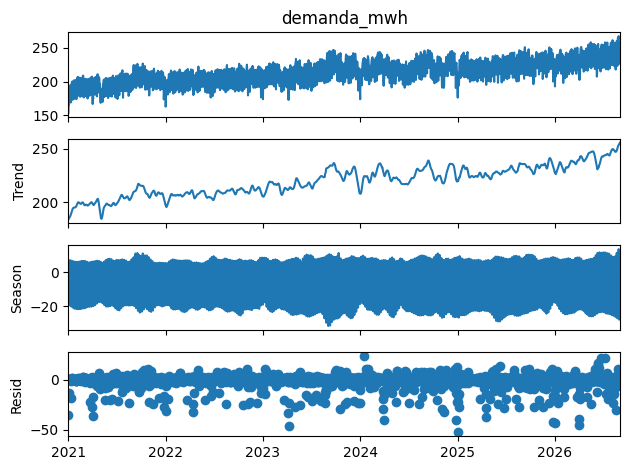

In [5]:
from statsmodels.tsa.seasonal import STL
diario = serie.resample("D").sum(min_count=24).dropna() / 1000
STL(diario, period=7, robust=True).fit().plot();

## Estacionalidad diaria y semanal

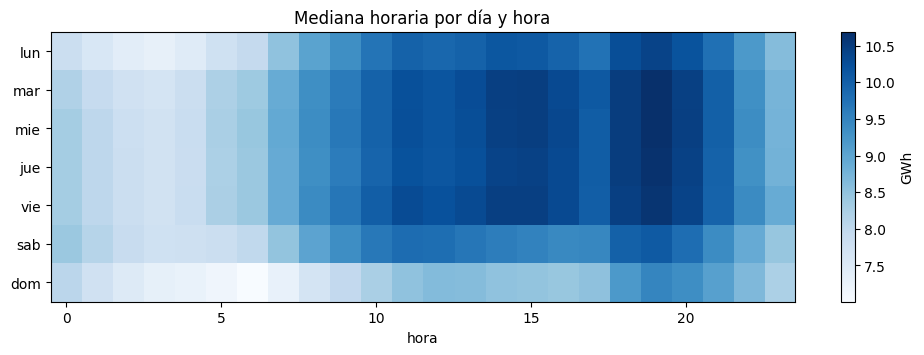

In [6]:
tabla = serie.groupby([serie.index.dayofweek, serie.index.hour]).median().unstack() / 1000
fig, eje = plt.subplots(figsize=(12, 3.5))
im = eje.imshow(tabla.values, aspect="auto", cmap="Blues")
eje.set_yticks(range(7), ["lun", "mar", "mie", "jue", "vie", "sab", "dom"]); eje.set_xlabel("hora")
fig.colorbar(im, ax=eje, label="GWh"); eje.set_title("Mediana horaria por día y hora");

ACF  1h  : 0.964
ACF 24h  : 0.857
ACF 168h : 0.924  <- la misma hora de la semana anterior pesa más que la del día anterior


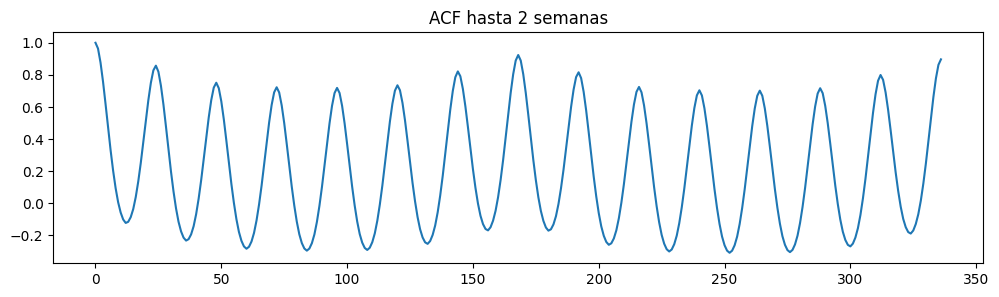

In [7]:
acf, pacf = eda.autocorrelacion(serie)
print("ACF  1h  :", round(acf[1], 3))
print("ACF 24h  :", round(acf[24], 3))
print("ACF 168h :", round(acf[168], 3), " <- la misma hora de la semana anterior pesa más que la del día anterior")
acf.plot(figsize=(12, 3), title="ACF hasta 2 semanas");

## Calendario colombiano (Ley Emiliani)

In [8]:
local = panel.set_index(eda.serie_mwh(panel).index)
festivo = local["es_festivo"].astype(bool).resample("D").max().reindex(diario.index)
tipos = eda.tipo_dia(diario.index, festivo)
pd.Series(eda.pruebas_calendario(diario * 1000, tipos))

variable                                                      demanda diaria / media del ano
medianas                                   {'laboral': 1.0302234126634033, 'sabado': 0.98...
n                                          {'laboral': 1387, 'sabado': 291, 'domingo': 29...
kruskal_h                                                                        1138.306833
kruskal_p                                                                                0.0
epsilon_cuadrado                                                                    0.549907
mannwhitney_festivo_menor_que_laboral_u                                               1139.0
mannwhitney_p                                                                            0.0
efecto_r_rank_biserial                                                              0.984054
festivo_vs_laboral_pct                                                            -12.341748
dtype: object

## Temperatura

{'spearman_horario': 0.694203786345722,
 'spearman_horario_p': 0.0,
 'spearman_anomalia_diaria': 0.26443241151431,
 'spearman_anomalia_diaria_p': 1.7824979435546464e-34,
 'temperatura_media': 18.718263781586998,
 'temperatura_min': 10.879,
 'temperatura_max': 28.767}

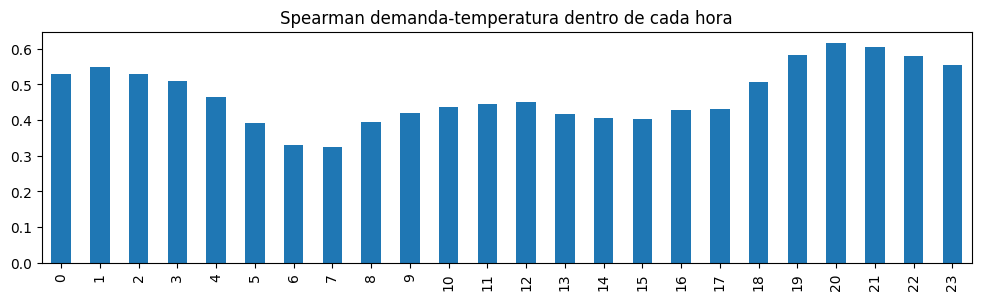

In [9]:
resultado = eda.temperatura(serie, local["temperatura_c"].reindex(serie.index))
pd.Series(resultado["spearman_por_hora"]).plot.bar(figsize=(12, 3), title="Spearman demanda-temperatura dentro de cada hora")
{k: v for k, v in resultado.items() if k != "spearman_por_hora"}

## Conclusiones para el modelado

- La serie tiene tendencia: un bosque no extrapola, así que se modelará la
  diferencia semanal o un componente lineal más un árbol sobre el residuo.
- `lag_168` es el rezago más informativo y la base estacional ingenua es la
  referencia obligatoria.
- Festivos y domingos se comportan igual: las banderas del calendario entran.
- El efecto de la temperatura depende de la hora: interacción que captura un
  árbol y no un modelo lineal.